# NYTimes - Midterm Election Week Report

In [67]:
import json
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import NYTimes_main as NYT
import prettytable as pt
import requests as rq

print(json.dumps(NYT.data["results"][0], indent=4))


{
    "uri": "nyt://interactive/8b34129d-6651-565c-8749-f3e74a4863ec",
    "url": "https://www.nytimes.com/interactive/2026/11/03/us/elections/results-house.html",
    "id": 100000011241930,
    "asset_id": 100000011241930,
    "source": "New York Times",
    "published_date": "2026-11-03",
    "updated": "2026-11-05 12:01:44",
    "section": "U.S.",
    "subsection": "Elections",
    "nytdsection": "u.s.",
    "adx_keywords": "Elections;Elections, House of Representatives;internal-disable-fab;Midterm Elections (2026);New Mexico;Nevada;New York;Ohio;Oklahoma;Oregon;Pennsylvania;Rhode Island;South Carolina;South Dakota;Tennessee;Texas;United States;Utah;Virginia;Vermont;Washington (State);Wisconsin;West Virginia;Wyoming;Iowa;Idaho;Illinois;Indiana;Kansas;Kentucky;Louisiana;Massachusetts;Maryland;Maine;Michigan;Minnesota;Missouri;Mississippi;Montana;North Carolina;North Dakota;Nebraska;New Hampshire;New Jersey;Alaska;Alabama;Arkansas;Arizona;California;Colorado;Connecticut;Delaware;Flori

In [68]:

df = pd.json_normalize(NYT.data["results"])

display(df.info(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   uri             20 non-null     object
 1   url             20 non-null     object
 2   id              20 non-null     int64 
 3   asset_id        20 non-null     int64 
 4   source          20 non-null     object
 5   published_date  20 non-null     object
 6   updated         20 non-null     object
 7   section         20 non-null     object
 8   subsection      20 non-null     object
 9   nytdsection     20 non-null     object
 10  adx_keywords    20 non-null     object
 11  column          0 non-null      object
 12  byline          20 non-null     object
 13  type            20 non-null     object
 14  title           20 non-null     object
 15  abstract        20 non-null     object
 16  des_facet       20 non-null     object
 17  org_facet       20 non-null     object
 18  per_facet   

None

In [69]:
display(df.head(5))

,uri,url,id,asset_id,source,published_date,updated,section,subsection,nytdsection,...,byline,type,title,abstract,des_facet,org_facet,per_facet,geo_facet,media,eta_id
0,nyt://interactive/8b34129d-6651-565c-8749-f3e7...,https://www.nytimes.com/interactive/2026/11/03...,100000011241930,100000011241930,New York Times,2026-11-03,2026-11-05 12:01:44,U.S.,Elections,u.s.,...,,Interactive,U.S. House Election Results,Follow the latest results from the 2026 midter...,"[Elections, Elections, House of Representative...",[],[],"[New Mexico, Nevada, New York, Ohio, Oklahoma,...","[{'type': 'image', 'subtype': '', 'caption': '...",0
1,nyt://interactive/44efd91f-6f8a-5ecd-8078-45e7...,https://www.nytimes.com/interactive/2026/11/03...,100000011241938,100000011241938,New York Times,2026-11-03,2026-11-05 12:02:01,U.S.,Elections,u.s.,...,,Interactive,Live Forecast: Senate and House,Follow real-time estimates of the outcome of t...,"[internal-disable-fab, Midterm Elections (2026...",[],[],"[Alaska, Alabama, Arkansas, Arizona, Californi...","[{'type': 'image', 'subtype': '', 'caption': '...",0
2,nyt://interactive/a846ab38-ebd9-5594-8da1-3ce8...,https://www.nytimes.com/interactive/2026/11/03...,0,0,New York Times,2026-11-03,2026-11-05 12:01:00,U.S.,Elections,u.s.,...,,Interactive,Mississippi U.S. Senate Election Results,Get live results and maps from the 2026 Missis...,"[Elections, Elections, Senate, internal-disabl...",[],[],[Mississippi],"[{'type': 'image', 'subtype': '', 'caption': '...",0
3,nyt://interactive/bfb6e9fe-0042-5dca-8e11-6ba7...,https://www.nytimes.com/interactive/2026/11/03...,0,0,New York Times,2026-11-03,2026-11-05 12:01:29,U.S.,Elections,u.s.,...,,Interactive,Texas Election Results,Get live results and maps from the 2026 Texas ...,"[Elections, Elections, Courts and the Judiciar...",[Railroad Commission of Texas],[],[Texas],"[{'type': 'image', 'subtype': '', 'caption': '...",0
4,nyt://article/126766da-af9e-566a-b965-c7c30410...,https://www.nytimes.com/2026/11/03/us/politics...,100000011256615,100000011256615,New York Times,2026-11-03,2026-11-04 09:42:01,U.S.,Politics,u.s.,...,By Erica L. Green and Tyler Pager,Article,Trump Says in Interview That He Will Accept El...,"In an interview with two Times reporters, Pres...","[Elections, Senate, Elections, House of Repres...","[Democratic Party, Republican Party]","[Trump, Donald J]",[],"[{'type': 'image', 'subtype': 'photo', 'captio...",0


In [70]:
#look at the sections and subsections of the articles by the publish date and the number of articles in each section and subsection.
df.groupby(['section', 'subsection']).size().reset_index(name='counts').sort_values(by='counts', ascending=False).head(10)


,section,subsection,counts
4,U.S.,Elections,11
5,U.S.,Politics,5
0,Arts,Television,1
1,New York,,1
2,Opinion,,1
3,U.S.,,1


In [71]:
df.columns

Index(['uri', 'url', 'id', 'asset_id', 'source', 'published_date', 'updated',
       'section', 'subsection', 'nytdsection', 'adx_keywords', 'column',
       'byline', 'type', 'title', 'abstract', 'des_facet', 'org_facet',
       'per_facet', 'geo_facet', 'media', 'eta_id'],
      dtype='object')

In [72]:
facebook_df = df[[
    "title",
    "section",
    "published_date",
    "url"
]].copy()

# API results are ordered by popularity
facebook_df["facebook_rank"] = range(1, len(facebook_df) + 1)

display(facebook_df)

,title,section,published_date,url,facebook_rank
0,U.S. House Election Results,U.S.,2026-11-03,https://www.nytimes.com/interactive/2026/11/03...,1
1,Live Forecast: Senate and House,U.S.,2026-11-03,https://www.nytimes.com/interactive/2026/11/03...,2
2,Mississippi U.S. Senate Election Results,U.S.,2026-11-03,https://www.nytimes.com/interactive/2026/11/03...,3
3,Texas Election Results,U.S.,2026-11-03,https://www.nytimes.com/interactive/2026/11/03...,4
4,Trump Says in Interview That He Will Accept El...,U.S.,2026-11-03,https://www.nytimes.com/2026/11/03/us/politics...,5
5,Ohio Election Results,U.S.,2026-11-03,https://www.nytimes.com/interactive/2026/11/03...,6
6,Inside the Abdul El-Sayed-Haley Stevens Meltdo...,U.S.,2026-11-01,https://www.nytimes.com/2026/11/01/us/politics...,7
7,Jet That Crashed in Florida Carried Texas Fami...,U.S.,2026-11-02,https://www.nytimes.com/2026/11/02/us/nathalia...,8
8,Governor Election Results,U.S.,2026-11-03,https://www.nytimes.com/interactive/2026/11/03...,9
9,Why Are We Having Less Sex? Ask a Pornographer.,Opinion,2026-10-29,https://www.nytimes.com/2026/10/29/opinion/int...,10


In [73]:
section_report = (
    facebook_df.groupby("section")
    .agg(
        article_count=("title", "count"),
        avg_rank=("facebook_rank", "mean")
    )
    .sort_values("article_count", ascending=False)
)

display(section_report)

,article_count,avg_rank
section,,
U.S.,17,9.823529
Arts,1,15.000000
New York,1,18.000000
Opinion,1,10.000000


In [74]:
# What are the most common topics right now
keywords = (
    df["adx_keywords"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
)

topic_report = (
    keywords[keywords.ne("")]
    .value_counts()
    .head(10)
)


topics = topics[topics.ne("")]
display(topic_report)

Midterm Elections (2026)               15
Elections, Senate                      13
Elections                              11
internal-disable-fab                   11
Elections, House of Representatives     8
Michigan                                6
Texas                                   6
Ohio                                    5
Mississippi                             5
Alaska                                  5
Name: adx_keywords, dtype: int64

In [75]:
#Count how often each topic appears 
topics = (
    df["adx_keywords"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
)

topics = topics[topics.ne("")]


topics = topics[topics.ne("")]
topic_counts = (
    topics.value_counts()
    .reset_index()
)

topic_counts.columns = ["topic", "article_count"]

display(topic_counts.head(15))

,topic,article_count
0,Midterm Elections (2026),15
1,"Elections, Senate",13
2,Elections,11
3,internal-disable-fab,11
4,"Elections, House of Representatives",8
5,Michigan,6
6,Texas,6
7,Ohio,5
8,Mississippi,5
9,Alaska,5


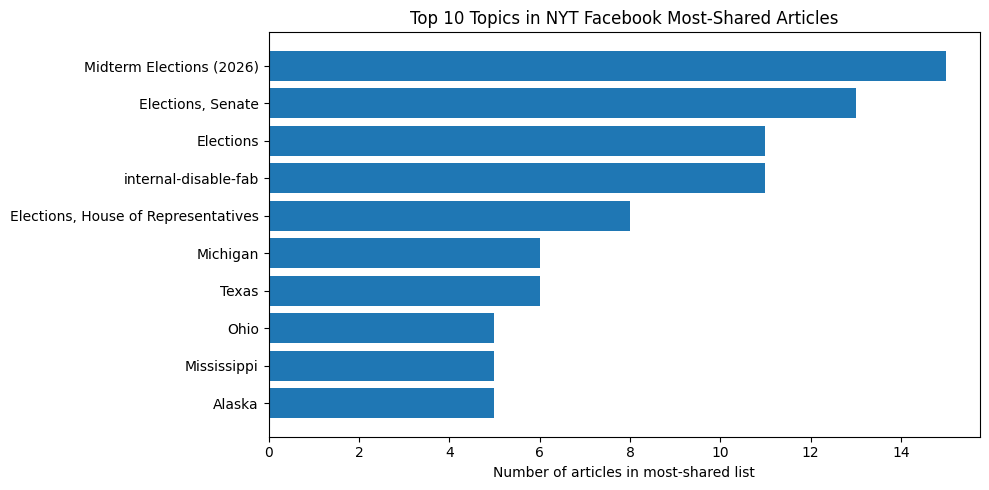

In [76]:
#Visualize the top 10 recurring topics

top10 = topic_counts.head(10)

plt.figure(figsize=(10, 5))

plt.barh(
    top10["topic"],
    top10["article_count"]
)

plt.xlabel("Number of articles in most-shared list")
plt.title("Top 10 Topics in NYT Facebook Most-Shared Articles")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [77]:
# Preserve the popularity order returned by the API
df["facebook_rank"] = range(1, len(df) + 1)

#print("Total articles:", len(df))
#print("Available columns:", df.columns.tolist())

# Show every row and column in the notebook
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.max_colwidth", 120
):
    display(df)
articles = df[[
    "facebook_rank",
    "title",
    "section",
    "published_date",
    "updated",
    "adx_keywords",
    "url"
]].copy()

articles["published_date"] = pd.to_datetime(
    articles["published_date"], utc=True
)

articles["updated"] = pd.to_datetime(
    articles["updated"], utc=True
)

articles["days_since_publication"] = (
    pd.Timestamp.now(tz="UTC") -
    articles["published_date"]
).dt.days

display(articles)

,uri,url,id,asset_id,source,published_date,updated,section,subsection,nytdsection,adx_keywords,column,byline,type,title,abstract,des_facet,org_facet,per_facet,geo_facet,media,eta_id,facebook_rank
0,nyt://interactive/8b34129d-6651-565c-8749-f3e74a4863ec,https://www.nytimes.com/interactive/2026/11/03/us/elections/results-house.html,100000011241930,100000011241930,New York Times,2026-11-03,2026-11-05 12:01:44,U.S.,Elections,u.s.,"Elections;Elections, House of Representatives;internal-disable-fab;Midterm Elections (2026);New Mexico;Nevada;New Yo...",None,,Interactive,U.S. House Election Results,Follow the latest results from the 2026 midterm elections.,"[Elections, Elections, House of Representatives, internal-disable-fab, Midterm Elections (2026)]",[],[],"[New Mexico, Nevada, New York, Ohio, Oklahoma, Oregon, Pennsylvania, Rhode Island, South Carolina, South Dakota, Ten...","[{'type': 'image', 'subtype': '', 'caption': '', 'copyright': 'The New York Times', 'approved_for_syndication': 1, '...",0,1
1,nyt://interactive/44efd91f-6f8a-5ecd-8078-45e7d4001b1e,https://www.nytimes.com/interactive/2026/11/03/us/elections/results-needle-senate-house-forecast.html,100000011241938,100000011241938,New York Times,2026-11-03,2026-11-05 12:02:01,U.S.,Elections,u.s.,"internal-disable-fab;Midterm Elections (2026);Elections;Elections, House of Representatives;Elections, Senate;Alaska...",None,,Interactive,Live Forecast: Senate and House,Follow real-time estimates of the outcome of the 2026 midterm elections from The New York Times.,"[internal-disable-fab, Midterm Elections (2026), Elections, Elections, House of Representatives, Elections, Senate]",[],[],"[Alaska, Alabama, Arkansas, Arizona, California, Colorado, Connecticut, Delaware, Florida, Georgia, Hawaii, Iowa, Id...","[{'type': 'image', 'subtype': '', 'caption': '', 'copyright': 'The New York Times', 'approved_for_syndication': 1, '...",0,2
2,nyt://interactive/a846ab38-ebd9-5594-8da1-3ce8119fbbbf,https://www.nytimes.com/interactive/2026/11/03/us/elections/results-mississippi-us-senate.html,0,0,New York Times,2026-11-03,2026-11-05 12:01:00,U.S.,Elections,u.s.,"Elections;Elections, Senate;internal-disable-fab;Midterm Elections (2026);Mississippi",None,,Interactive,Mississippi U.S. Senate Election Results,Get live results and maps from the 2026 Mississippi general election.,"[Elections, Elections, Senate, internal-disable-fab, Midterm Elections (2026)]",[],[],[Mississippi],"[{'type': 'image', 'subtype': '', 'caption': '', 'copyright': 'The New York Times', 'approved_for_syndication': 1, '...",0,3
3,nyt://interactive/bfb6e9fe-0042-5dca-8e11-6ba73bdd94e3,https://www.nytimes.com/interactive/2026/11/03/us/elections/results-texas.html,0,0,New York Times,2026-11-03,2026-11-05 12:01:29,U.S.,Elections,u.s.,"Elections;Elections, Courts and the Judiciary;Elections, Attorneys General;Elections, City Councils;Elections, Compt...",None,,Interactive,Texas Election Results,Get live results and maps from the 2026 Texas elections.,"[Elections, Elections, Courts and the Judiciary, Elections, Attorneys General, Elections, City Councils, Elections, ...",[Railroad Commission of Texas],[],[Texas],"[{'type': 'image', 'subtype': '', 'caption': '', 'copyright': 'The New York Times', 'approved_for_syndication': 1, '...",0,4
4,nyt://article/126766da-af9e-566a-b965-c7c304107555,https://www.nytimes.com/2026/11/03/us/politics/trump-midterm-election-results.html,100000011256615,100000011256615,New York Times,2026-11-03,2026-11-04 09:42:01,U.S.,Politics,u.s.,"Elections, Senate;Elections, House of Representatives;Midterm Elections (2026);United States Politics and Government...",None,By Erica L. Green and Tyler Pager,Article,Trump Says in Interview That He Will Accept Election Results,"In an interview with two Times reporters, President Trump blamed the G.O.P.’s losses on the fact that he was not on ...","[Elections, Senate, Elections, House of Representatives, Midterm Elections (2026), United States Politics and Govern...","[D

,facebook_rank,title,section,published_date,updated,adx_keywords,url,days_since_publication
0,1,U.S. House Election Results,U.S.,2026-11-03 00:00:00+00:00,2026-11-05 12:01:44+00:00,"Elections;Elections, House of Representatives;...",https://www.nytimes.com/interactive/2026/11/03...,2
1,2,Live Forecast: Senate and House,U.S.,2026-11-03 00:00:00+00:00,2026-11-05 12:02:01+00:00,internal-disable-fab;Midterm Elections (2026);...,https://www.nytimes.com/interactive/2026/11/03...,2
2,3,Mississippi U.S. Senate Election Results,U.S.,2026-11-03 00:00:00+00:00,2026-11-05 12:01:00+00:00,"Elections;Elections, Senate;internal-disable-f...",https://www.nytimes.com/interactive/2026/11/03...,2
3,4,Texas Election Results,U.S.,2026-11-03 00:00:00+00:00,2026-11-05 12:01:29+00:00,"Elections;Elections, Courts and the Judiciary;...",https://www.nytimes.com/interactive/2026/11/03...,2
4,5,Trump Says in Interview That He Will Accept El...,U.S.,2026-11-03 00:00:00+00:00,2026-11-04 09:42:01+00:00,"Elections, Senate;Elections, House of Represen...",https://www.nytimes.com/2026/11/03/us/politics...,2
5,6,Ohio Election Results,U.S.,2026-11-03 00:00:00+00:00,2026-11-05 12:00:58+00:00,"Elections;Elections, Attorneys General;Electio...",https://www.nytimes.com/interactive/2026/11/03...,2
6,7,Inside the Abdul El-Sayed-Haley Stevens Meltdo...,U.S.,2026-11-01 00:00:00+00:00,2026-11-02 20:41:45+00:00,"Midterm Elections (2026);Elections, Senate;Uni...",https://www.nytimes.com/2026/11/01/us/politics...,4
7,8,Jet That Crashed in Florida Carried Texas Fami...,U.S.,2026-11-02 00:00:00+00:00,2026-11-03 14:29:03+00:00,"Aviation Accidents, Safety and Disasters;Death...",https://www.nytimes.com/2026/11/02/us/nathalia...,3
8,9,Governor Election Results,U.S.,2026-11-03 00:00:00+00:00,2026-11-05 12:02:00+00:00,"Elections;Elections, Governors;internal-disabl...",https://www.nytimes.com/interactive/2026/11/03...,2
9,10,Why Are We Having Less Sex? Ask a Pornographer.,Opinion,2026-10-29 00:00:00+00:00,2026-10-30 15:44:24+00:00,audio-neutral-informative;Pornography;Sex;Wome...,https://www.nytimes.com/2026/10/29/opinion/int...,7


In [78]:
topic_df = (
    articles.assign(
        topic=articles["adx_keywords"].fillna("").str.split(";")
    )
    .explode("topic")
)

topic_df["topic"] = topic_df["topic"].str.strip()
topic_df = topic_df[topic_df["topic"] != ""]

topic_summary = (
    topic_df.groupby("topic")
    .agg(
        article_count=("title", "count"),
        average_rank=("facebook_rank", "mean")
    )
    .sort_values(
        ["article_count", "average_rank"],
        ascending=[False, True]
    )
    .reset_index()
)

display(topic_summary.head(30))

,topic,article_count,average_rank
0,Midterm Elections (2026),15,9.800000
1,"Elections, Senate",13,10.538462
2,Elections,11,9.272727
3,internal-disable-fab,11,9.272727
4,"Elections, House of Representatives",8,8.750000
5,Texas,6,7.833333
6,Michigan,6,8.666667
7,Ohio,5,7.600000
8,Mississippi,5,9.000000
9,Alaska,5,9.200000


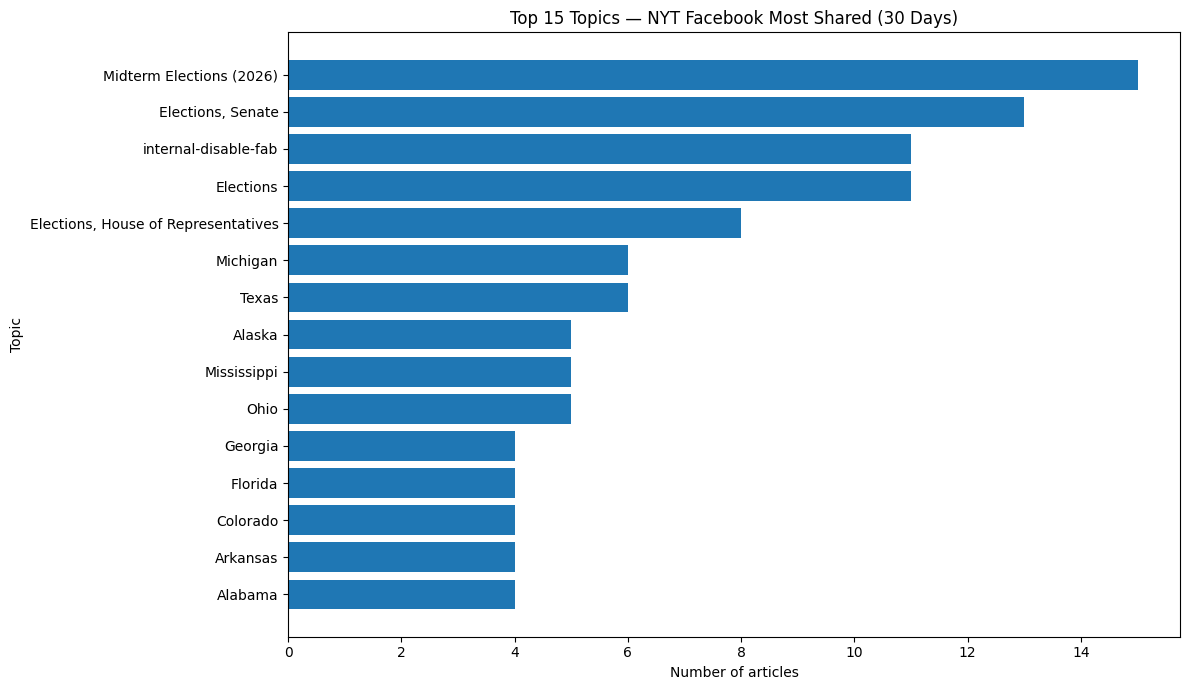

In [79]:
top15 = topic_summary.head(15).sort_values("article_count")

plt.figure(figsize=(12, 7))

plt.barh(
    top15["topic"],
    top15["article_count"]
)

plt.xlabel("Number of articles")
plt.ylabel("Topic")
plt.title("Top 15 Topics — NYT Facebook Most Shared (30 Days)")
plt.tight_layout()
plt.show()

,section,article_count,average_rank
0,U.S.,17,9.823529
1,Arts,1,15.000000
2,New York,1,18.000000
3,Opinion,1,10.000000


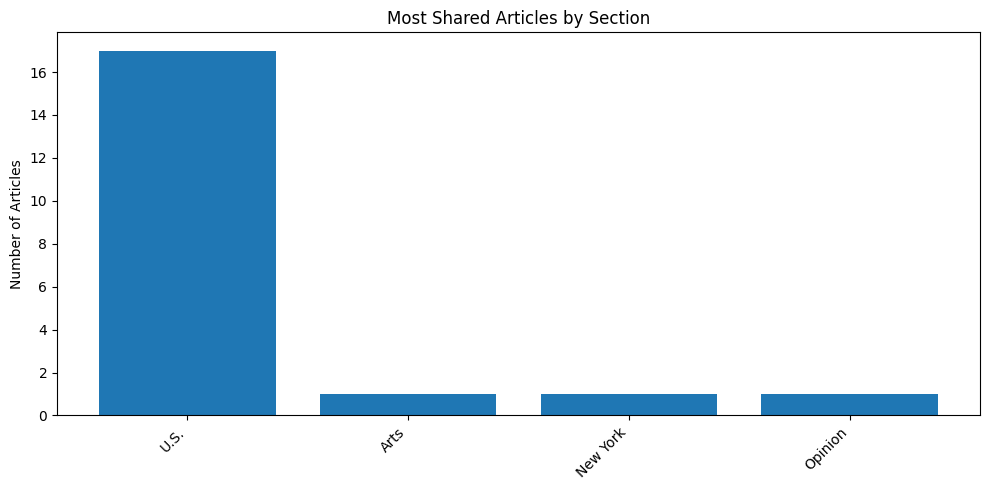

In [80]:
section_summary = (
    articles.groupby("section")
    .agg(
        article_count=("title", "count"),
        average_rank=("facebook_rank", "mean")
    )
    .sort_values("article_count", ascending=False)
    .reset_index()
)

display(section_summary)

plt.figure(figsize=(10, 5))
plt.bar(
    section_summary["section"],
    section_summary["article_count"]
)

plt.xticks(rotation=45, ha="right")
plt.title("Most Shared Articles by Section")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.show()

In [81]:
#Compare recent 14-day articles with the 30-day list
 
cutoff = pd.Timestamp.now(tz="UTC") - pd.Timedelta(days=14)

recent_14 = articles[
    articles["published_date"] >= cutoff
].copy()

print("Articles published within last 14 days:", len(recent_14))

display(recent_14)

Articles published within last 14 days: 20


,facebook_rank,title,section,published_date,updated,adx_keywords,url,days_since_publication
0,1,U.S. House Election Results,U.S.,2026-11-03 00:00:00+00:00,2026-11-05 12:01:44+00:00,"Elections;Elections, House of Representatives;...",https://www.nytimes.com/interactive/2026/11/03...,2
1,2,Live Forecast: Senate and House,U.S.,2026-11-03 00:00:00+00:00,2026-11-05 12:02:01+00:00,internal-disable-fab;Midterm Elections (2026);...,https://www.nytimes.com/interactive/2026/11/03...,2
2,3,Mississippi U.S. Senate Election Results,U.S.,2026-11-03 00:00:00+00:00,2026-11-05 12:01:00+00:00,"Elections;Elections, Senate;internal-disable-f...",https://www.nytimes.com/interactive/2026/11/03...,2
3,4,Texas Election Results,U.S.,2026-11-03 00:00:00+00:00,2026-11-05 12:01:29+00:00,"Elections;Elections, Courts and the Judiciary;...",https://www.nytimes.com/interactive/2026/11/03...,2
4,5,Trump Says in Interview That He Will Accept El...,U.S.,2026-11-03 00:00:00+00:00,2026-11-04 09:42:01+00:00,"Elections, Senate;Elections, House of Represen...",https://www.nytimes.com/2026/11/03/us/politics...,2
5,6,Ohio Election Results,U.S.,2026-11-03 00:00:00+00:00,2026-11-05 12:00:58+00:00,"Elections;Elections, Attorneys General;Electio...",https://www.nytimes.com/interactive/2026/11/03...,2
6,7,Inside the Abdul El-Sayed-Haley Stevens Meltdo...,U.S.,2026-11-01 00:00:00+00:00,2026-11-02 20:41:45+00:00,"Midterm Elections (2026);Elections, Senate;Uni...",https://www.nytimes.com/2026/11/01/us/politics...,4
7,8,Jet That Crashed in Florida Carried Texas Fami...,U.S.,2026-11-02 00:00:00+00:00,2026-11-03 14:29:03+00:00,"Aviation Accidents, Safety and Disasters;Death...",https://www.nytimes.com/2026/11/02/us/nathalia...,3
8,9,Governor Election Results,U.S.,2026-11-03 00:00:00+00:00,2026-11-05 12:02:00+00:00,"Elections;Elections, Governors;internal-disabl...",https://www.nytimes.com/interactive/2026/11/03...,2
9,10,Why Are We Having Less Sex? Ask a Pornographer.,Opinion,2026-10-29 00:00:00+00:00,2026-10-30 15:44:24+00:00,audio-neutral-informative;Pornography;Sex;Wome...,https://www.nytimes.com/2026/10/29/opinion/int...,7


In [82]:
#Compare topics: Recent 14 days vs. all 30 days
def count_topics(data):
    return (
        data["adx_keywords"]
        .fillna("")
        .str.split(";")
        .explode()
        .str.strip()
        .loc[lambda s: s.ne("")]
        .value_counts()
    )

topics_30 = count_topics(articles)
topics_14 = count_topics(recent_14)

comparison = pd.concat(
    [
        topics_30.rename("articles_30d_list"),
        topics_14.rename("articles_published_last_14d")
    ],
    axis=1
).fillna(0).astype(int)

comparison["recent_article_share"] = (
    comparison["articles_published_last_14d"] /
    comparison["articles_30d_list"]
).round(2)

comparison = comparison.sort_values(
    ["articles_published_last_14d", "articles_30d_list"],
    ascending=False
)

display(comparison.head(30))

,articles_30d_list,articles_published_last_14d,recent_article_share
Midterm Elections (2026),15,15,1.0
"Elections, Senate",13,13,1.0
Elections,11,11,1.0
internal-disable-fab,11,11,1.0
"Elections, House of Representatives",8,8,1.0
Michigan,6,6,1.0
Texas,6,6,1.0
Ohio,5,5,1.0
Mississippi,5,5,1.0
Alaska,5,5,1.0


In [83]:
pm_insights = topic_summary.head(10).copy()

pm_insights["potential_action"] = (
    "Investigate topic for editorial discovery and distribution"
)

display(pm_insights)

,topic,article_count,average_rank,potential_action
0,Midterm Elections (2026),15,9.800000,Investigate topic for editorial discovery and ...
1,"Elections, Senate",13,10.538462,Investigate topic for editorial discovery and ...
2,Elections,11,9.272727,Investigate topic for editorial discovery and ...
3,internal-disable-fab,11,9.272727,Investigate topic for editorial discovery and ...
4,"Elections, House of Representatives",8,8.750000,Investigate topic for editorial discovery and ...
5,Texas,6,7.833333,Investigate topic for editorial discovery and ...
6,Michigan,6,8.666667,Investigate topic for editorial discovery and ...
7,Ohio,5,7.600000,Investigate topic for editorial discovery and ...
8,Mississippi,5,9.000000,Investigate topic for editorial discovery and ...
9,Alaska,5,9.200000,Investigate topic for editorial discovery and ...


In [84]:

df["published_date"] = pd.to_datetime(
    df["published_date"], utc=True
)

cutoff = pd.Timestamp.now(tz="UTC") - pd.Timedelta(days=30)

trump_articles = df[
    (df["published_date"] >= cutoff) &
    (
        df["adx_keywords"].fillna("").str.contains(
            r"Trump, Donald J", case=False, regex=False
        )
        |
        df["title"].fillna("").str.contains(
            "Trump", case=False, regex=False
        )
    )
].copy()

print("Trump-related articles:", len(trump_articles))

display(
    trump_articles[
        ["published_date", "title", "section", "url"]
    ].sort_values("published_date", ascending=False)
)

Trump-related articles: 4


,published_date,title,section,url
15,2026-11-04 00:00:00+00:00,"After Midterm Drubbing, Trump and Republicans ...",U.S.,https://www.nytimes.com/2026/11/04/us/politics...
16,2026-11-04 00:00:00+00:00,"‘I Have Seen the Enemy, and It Is Us’: Inside ...",U.S.,https://www.nytimes.com/2026/11/04/us/politics...
4,2026-11-03 00:00:00+00:00,Trump Says in Interview That He Will Accept El...,U.S.,https://www.nytimes.com/2026/11/03/us/politics...
11,2026-10-29 00:00:00+00:00,Trump Erupted After Learning of Alina Habba’s ...,U.S.,https://www.nytimes.com/2026/10/29/us/politics...
